# Лабораторная работа № 2. Классификация табличных данных и нейронные сети

**Цель:** исследовать классификацию категориальной целевой переменной по признакам табличного набора данных; сравнить методы Scikit-learn, подобрать гиперпараметры и обучить нейронную сеть TensorFlow.

**Набор данных:** Breast Cancer Wisconsin (Diagnostic), доступный через `sklearn.datasets.load_breast_cancer`.

**Объект исследования:** строка таблицы с числовыми характеристиками клеточных ядер, измеренными по результатам исследования образца ткани. **Целевая категориальная переменная:** тип диагноза — доброкачественный (0) или злокачественный (1). Это **классификация строк таблицы, а не изображений**. Всего 569 строк и 30 числовых признаков.

**Важно:** после замены исходного датасета старые значения метрик и графики неприменимы. Необходимо выполнить ноутбук заново; выводы ниже формируются из новых результатов.


## 1. Настройка окружения


Python 3.10–3.12 рекомендуется для совместимости с TensorFlow. Установите зависимости **в терминале VS Code** командой:
'''powershell
python -m pip install numpy pandas matplotlib scikit-learn tensorflow tensorboard ipykernel



In [1]:
%pip install tensorflow
%pip install numpy

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 23.0.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip



[notice] A new release of pip is available: 23.0.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
import sys

print("Версия Python:", sys.version)
print("Путь к Python:", sys.executable)

import numpy
import tensorflow as tf

print("Python:", sys.version)
print("NumPy:", numpy.__version__)
print("TensorFlow:", tf.__version__)

Версия Python: 3.10.11 (tags/v3.10.11:7d4cc5a, Apr  5 2023, 00:38:17) [MSC v.1929 64 bit (AMD64)]
Путь к Python: c:\Users\anast\AppData\Local\Programs\Python\Python310\python.exe
Python: 3.10.11 (tags/v3.10.11:7d4cc5a, Apr  5 2023, 00:38:17) [MSC v.1929 64 bit (AMD64)]
NumPy: 2.2.6
TensorFlow: 2.21.0


In [3]:
from pathlib import Path
import os, random, json, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV, validation_curve
from sklearn.preprocessing import StandardScaler, MinMaxScaler, Binarizer
from sklearn.pipeline import Pipeline
from sklearn.naive_bayes import GaussianNB, MultinomialNB, ComplementNB, BernoulliNB
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, confusion_matrix, ConfusionMatrixDisplay, roc_curve
SEED=42
np.random.seed(SEED); random.seed(SEED)
OUT=Path('results_lab2'); OUT.mkdir(exist_ok=True)
plt.rcParams.update({'font.family':'DejaVu Sans','axes.grid':True,'grid.alpha':0.2,'figure.dpi':110})
print('Рабочая папка:',Path.cwd())
print('Каталог результатов:',OUT)

Рабочая папка: c:\Users\anast\Downloads
Каталог результатов: results_lab2


**Вывод по разделу 1.** Импортированы библиотеки анализа табличных данных, классификации и нейронных сетей. Версии и успешность установки определяются выводом ячеек выше; прежние версии программ из эксперимента с цифрами не используются как результат новой работы.


## 2. Загрузка и первичный анализ данных

Используется табличный набор **Breast Cancer Wisconsin (Diagnostic)**. Одна строка соответствует наблюдению, 30 столбцов признаков содержат числовые измерения характеристик клеточных ядер. Целевая переменная — **категория диагноза**: `0` — доброкачественный, `1` — злокачественный. Положительный класс специально кодируется единицей, чтобы Precision, Recall и ROC-AUC относились к выявлению злокачественных случаев.

Ниже выводятся размерность, пропуски, статистики, баланс классов и распределения отдельных признаков.


Наблюдений: 569 Признаков: 30
Пропусков: 0


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst radius,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678


,count,mean,std,min,25%,50%,75%,max
mean radius,569.0,14.13,3.52,6.98,11.70,13.37,15.78,28.11
mean texture,569.0,19.29,4.30,9.71,16.17,18.84,21.80,39.28
mean perimeter,569.0,91.97,24.30,43.79,75.17,86.24,104.10,188.50
mean area,569.0,654.89,351.91,143.50,420.30,551.10,782.70,2501.00
mean smoothness,569.0,0.10,0.01,0.05,0.09,0.10,0.11,0.16
mean compactness,569.0,0.10,0.05,0.02,0.06,0.09,0.13,0.35
mean concavity,569.0,0.09,0.08,0.00,0.03,0.06,0.13,0.43
mean concave points,569.0,0.05,0.04,0.00,0.02,0.03,0.07,0.20
mean symmetry,569.0,0.18,0.03,0.11,0.16,0.18,0.20,0.30
mean fractal dimension,569.0,0.06,0.01,0.05,0.06,0.06,0.07,0.10


,Класс,Количество
0,Доброкачественный (0),357
1,Злокачественный (1),212


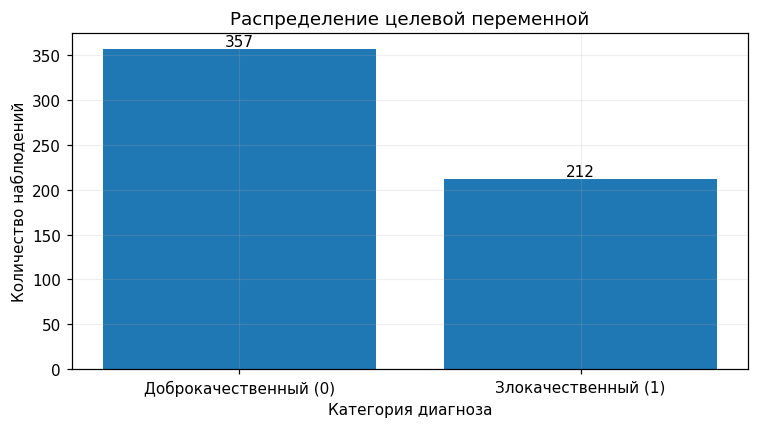

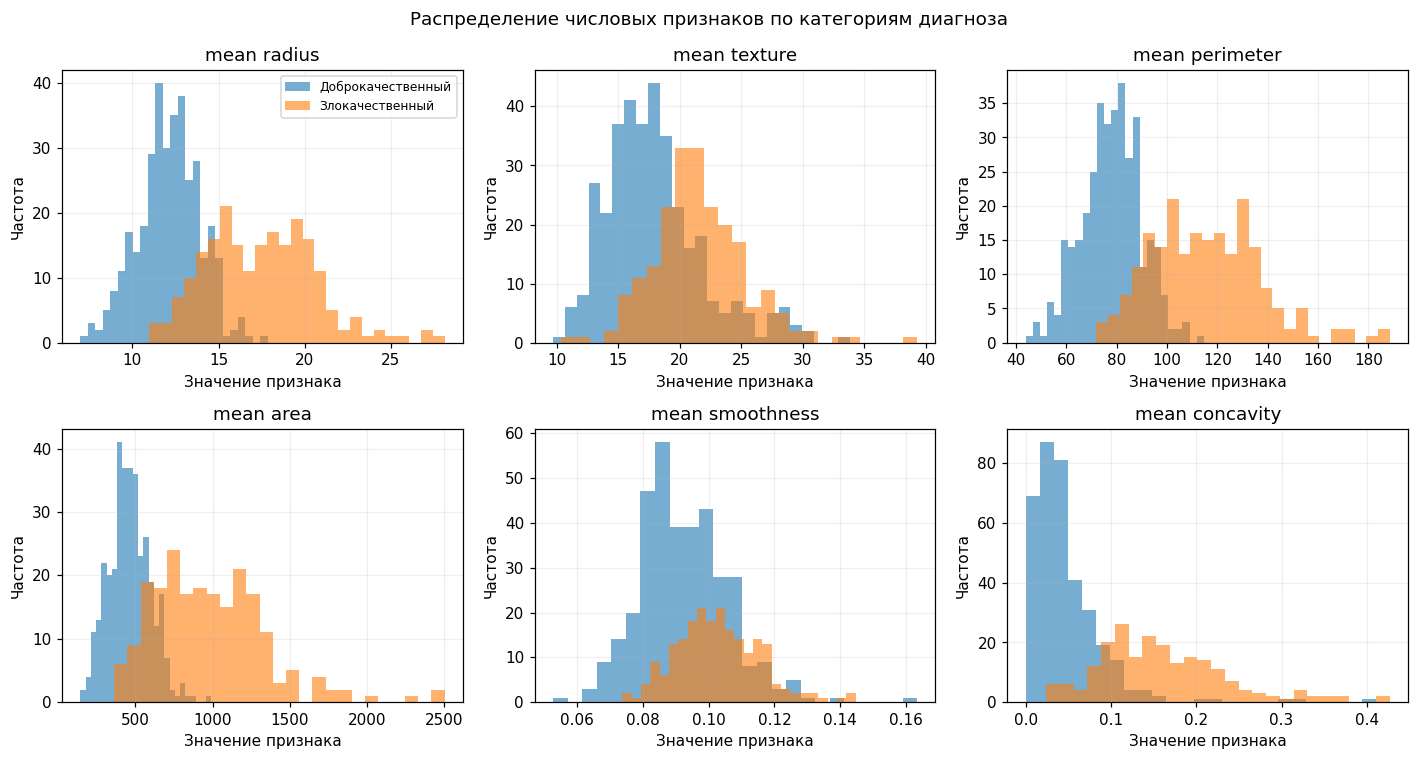

Вывод: таблица содержит 569 наблюдений и 30 числовых признаков; пропусков — 0. Доброкачественных случаев — 357 (62.7%), злокачественных — 212 (37.3%).


In [4]:
dataset = load_breast_cancer()
X = pd.DataFrame(dataset.data, columns=dataset.feature_names)
y = pd.Series((dataset.target == 0).astype(int), name='Злокачественный диагноз')
print('Наблюдений:', len(X), 'Признаков:', X.shape[1])
print('Пропусков:', int(X.isna().sum().sum()))
display(X.head())
display(X.describe().T.round(2))
class_table = pd.DataFrame({
    'Класс': ['Доброкачественный (0)', 'Злокачественный (1)'],
    'Количество': [int((y == 0).sum()), int((y == 1).sum())]
})
display(class_table)
fig, ax = plt.subplots(figsize=(7, 4))
bars = ax.bar(class_table['Класс'], class_table['Количество'])
ax.bar_label(bars)
ax.set(xlabel='Категория диагноза', ylabel='Количество наблюдений', title='Распределение целевой переменной')
fig.tight_layout(); fig.savefig(OUT/'classes.png', dpi=180); plt.show()
fig, axes = plt.subplots(2, 3, figsize=(13, 7))
feature_names = ['mean radius', 'mean texture', 'mean perimeter', 'mean area', 'mean smoothness', 'mean concavity']
for ax, col in zip(axes.flat, feature_names):
    ax.hist(X.loc[y == 0, col], bins=25, alpha=.6, label='Доброкачественный')
    ax.hist(X.loc[y == 1, col], bins=25, alpha=.6, label='Злокачественный')
    ax.set(title=col, xlabel='Значение признака', ylabel='Частота')
axes[0, 0].legend(fontsize=8)
fig.suptitle('Распределение числовых признаков по категориям диагноза')
fig.tight_layout(); fig.savefig(OUT/'features.png', dpi=180); plt.show()
print(f'Вывод: таблица содержит {len(X)} наблюдений и {X.shape[1]} числовых признаков; '
      f'пропусков — {int(X.isna().sum().sum())}. '
      f'Доброкачественных случаев — {int((y == 0).sum())} ({(y == 0).mean():.1%}), '
      f'злокачественных — {int((y == 1).sum())} ({(y == 1).mean():.1%}).')


**Вывод по разделу 2.** В отличие от распознавания цифр, здесь анализируется **категориальная переменная в таблице**. Признаки числовые, целевая переменная бинарная. Баланс классов и количество пропусков рассчитываются непосредственно в ячейке выше. Гистограммы позволяют увидеть, какие характеристики отличаются между категориями диагноза; пересечение распределений показывает, что отдельного признака может быть недостаточно для безошибочной классификации.


## 3. Подготовка выборок

Данные делятся на обучающую и тестовую части в пропорции 80/20 с сохранением долей категорий (`stratify=y`). На обучающей части используется пятиблочная стратифицированная кросс-валидация. Масштабирование и преобразования признаков помещены в `Pipeline`, чтобы не использовать информацию из проверочных и тестовых наблюдений при обучении.


In [5]:
Xtr,Xte,ytr,yte=train_test_split(X,y,test_size=.2,stratify=y,random_state=SEED)
cv=StratifiedKFold(n_splits=5,shuffle=True,random_state=SEED)
print('Обучающая выборка:',Xtr.shape,'Тестовая выборка:',Xte.shape)
print('Доля положительного класса: обучение',round(ytr.mean(),3),'тест',round(yte.mean(),3))
assert not Xtr.isna().any().any() and not Xte.isna().any().any()

Обучающая выборка: (455, 30) Тестовая выборка: (114, 30)
Доля положительного класса: обучение 0.374 тест 0.368


In [6]:
print(f"Вывод по разбиению: обучение — {len(Xtr)} строк, тест — {len(Xte)} строк. "
      f"Доля злокачественных диагнозов: {ytr.mean():.1%} и {yte.mean():.1%} соответственно.")


Вывод по разбиению: обучение — 455 строк, тест — 114 строк. Доля злокачественных диагнозов: 37.4% и 36.8% соответственно.


**Вывод по разделу 3.** Размеры обучающей и тестовой таблиц, а также доли положительного класса напечатаны выше. Стратификация позволяет сохранить сопоставимое распределение диагнозов. Тестовая часть отложена для итоговой оценки и не участвует в подборе гиперпараметров.


## 4. Обучение и подбор гиперпараметров

Рассматриваются **8 классификаторов** в рамках пяти семейств: четыре вида наивного Байеса, дерево решений, LDA, SVM и kNN. Для MultinomialNB/ComplementNB необходимы неотрицательные признаки — используется MinMaxScaler. Для BernoulliNB — бинаризация после MinMaxScaler. Для GaussianNB, LDA, SVM и kNN — стандартизация. Параметры подбираются по ROC-AUC с пятиблочной кросс-валидацией.

**Метрики:** Accuracy — доля верных прогнозов; Precision — точность положительных предсказаний; Recall — полнота положительного класса; F1 — гармоническое среднее Precision и Recall; ROC-AUC — способность ранжировать положительные объекты выше отрицательных.

In [7]:
specs={
 'Гауссовский Байес':(Pipeline([('scale',StandardScaler()),('model',GaussianNB())]),{'model__var_smoothing':[1e-12,1e-9,1e-6,1e-3]}),
 'Мультиномиальный Байес':(Pipeline([('scale',MinMaxScaler()),('model',MultinomialNB())]),{'model__alpha':[.01,.1,1,10]}),
 'Комплементарный Байес':(Pipeline([('scale',MinMaxScaler()),('model',ComplementNB())]),{'model__alpha':[.01,.1,1,10]}),
 'Бернуллиевский Байес':(Pipeline([('scale',MinMaxScaler()),('binary',Binarizer()),('model',BernoulliNB())]),{'binary__threshold':[.15,.3,.5,.7],'model__alpha':[.1,1]}),
 'Дерево решений':(Pipeline([('model',DecisionTreeClassifier(random_state=SEED))]),{'model__max_depth':[2,3,4,6,None],'model__min_samples_leaf':[1,3,7]}),
 'Линейный дискриминантный анализ':(Pipeline([('scale',StandardScaler()),('model',LinearDiscriminantAnalysis())]),{'model__solver':['svd','lsqr'],'model__shrinkage':[None]}),
 'Метод опорных векторов':(Pipeline([('scale',StandardScaler()),('model',SVC(probability=True,random_state=SEED))]),{'model__C':[.1,1,10,100],'model__kernel':['linear','rbf'],'model__gamma':['scale']}),
 'Метод ближайших соседей':(Pipeline([('scale',StandardScaler()),('model',KNeighborsClassifier())]),{'model__n_neighbors':[3,5,7,11,15],'model__weights':['uniform','distance']})
}
models={};rows=[];tuning=[]
for name,(pipeline,grid) in specs.items():
    search = GridSearchCV(
    estimator=pipeline,
    param_grid=grid,
    cv=cv,
    scoring='roc_auc',
    n_jobs=1,
    refit=True,
    error_score='raise'
)
    search.fit(Xtr,ytr)
    model=search.best_estimator_;models[name]=model
    pred=model.predict(Xte);score=model.predict_proba(Xte)[:,1]
    rows.append({'Модель':name,'Accuracy':accuracy_score(yte,pred),'Precision':precision_score(yte,pred,zero_division=0),'Recall':recall_score(yte,pred,zero_division=0),'F1':f1_score(yte,pred,zero_division=0),'ROC-AUC':roc_auc_score(yte,score),'CV ROC-AUC':search.best_score_})
    tuning.append({'Модель':name,'Лучшие параметры':str(search.best_params_),'CV ROC-AUC':search.best_score_})
metrics=pd.DataFrame(rows).sort_values('ROC-AUC',ascending=False).reset_index(drop=True)
display(metrics.round(4));display(pd.DataFrame(tuning))
metrics.to_csv(OUT/'classification_metrics.csv',index=False,encoding='utf-8-sig')
pd.DataFrame(tuning).to_csv(OUT/'best_parameters.csv',index=False,encoding='utf-8-sig')

,Модель,Accuracy,Precision,Recall,F1,ROC-AUC,CV ROC-AUC
0,Линейный дискриминантный анализ,0.9649,1.0000,0.9048,0.9500,0.9970,0.9938
1,Метод опорных векторов,0.9737,1.0000,0.9286,0.9630,0.9947,0.9949
2,Гауссовский Байес,0.9211,0.9231,0.8571,0.8889,0.9891,0.9870
3,Бернуллиевский Байес,0.9386,0.9487,0.8810,0.9136,0.9876,0.9835
4,Метод ближайших соседей,0.9474,0.9737,0.8810,0.9250,0.9823,0.9892
5,Дерево решений,0.9123,0.9000,0.8571,0.8780,0.9570,0.9571
6,Комплементарный Байес,0.8070,0.7174,0.7857,0.7500,0.9276,0.9225
7,Мультиномиальный Байес,0.8246,1.0000,0.5238,0.6875,0.9276,0.9225


,Модель,Лучшие параметры,CV ROC-AUC
0,Гауссовский Байес,{'model__var_smoothing': 1e-12},0.986997
1,Мультиномиальный Байес,{'model__alpha': 0.01},0.922497
2,Комплементарный Байес,{'model__alpha': 0.01},0.922497
3,Бернуллиевский Байес,"{'binary__threshold': 0.3, 'model__alpha': 0.1}",0.983488
4,Дерево решений,"{'model__max_depth': None, 'model__min_samples...",0.957121
5,Линейный дискриминантный анализ,"{'model__shrinkage': None, 'model__solver': 's...",0.993808
6,Метод опорных векторов,"{'model__C': 1, 'model__gamma': 'scale', 'mode...",0.994943
7,Метод ближайших соседей,"{'model__n_neighbors': 11, 'model__weights': '...",0.989216


In [8]:
leader = metrics.iloc[0]
laggard = metrics.iloc[-1]
print(f"Вывод по классификаторам: наибольший ROC-AUC у модели «{leader['Модель']}» "
      f"({leader['ROC-AUC']:.4f}); Accuracy={leader['Accuracy']:.4f}, "
      f"Precision={leader['Precision']:.4f}, Recall={leader['Recall']:.4f}, F1={leader['F1']:.4f}.")
print(f"Наименьший ROC-AUC у модели «{laggard['Модель']}» ({laggard['ROC-AUC']:.4f}). "
      f"Разница по ROC-AUC составляет {leader['ROC-AUC'] - laggard['ROC-AUC']:.4f}.")


Вывод по классификаторам: наибольший ROC-AUC у модели «Линейный дискриминантный анализ» (0.9970); Accuracy=0.9649, Precision=1.0000, Recall=0.9048, F1=0.9500.
Наименьший ROC-AUC у модели «Мультиномиальный Байес» (0.9276). Разница по ROC-AUC составляет 0.0694.


**Вывод по разделу 4.** В таблице выше представлены **новые** значения Accuracy, Precision, Recall, F1 и ROC-AUC для восьми методов. Метрики относятся к выявлению злокачественного диагноза (класс 1). ROC-AUC оценивает качество ранжирования наблюдений по вероятности положительного класса; Recall особенно важна для оценки пропущенных положительных случаев. Конкретный победитель и разница между моделями определяются по выполненной ячейке, а не по старым результатам распознавания цифр.


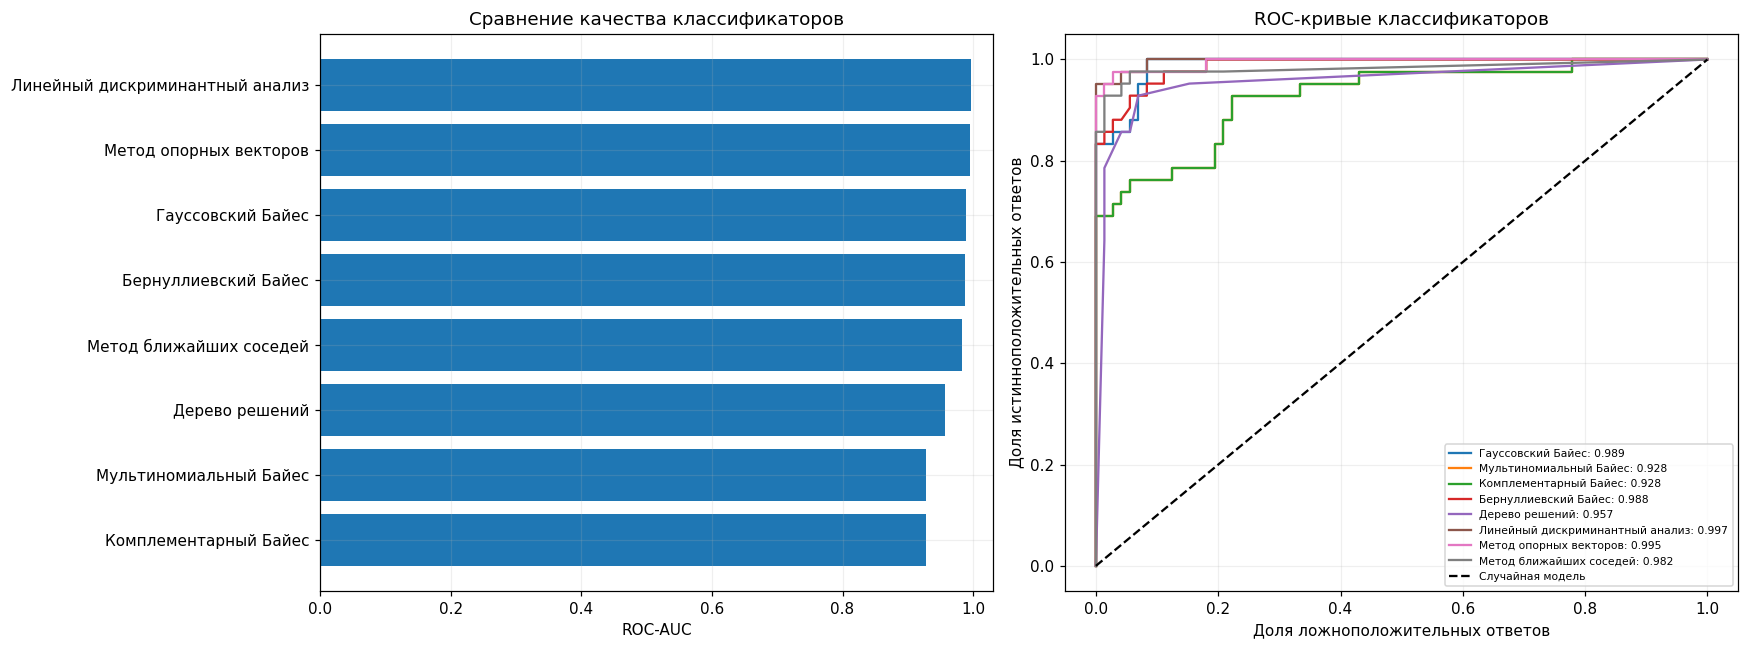

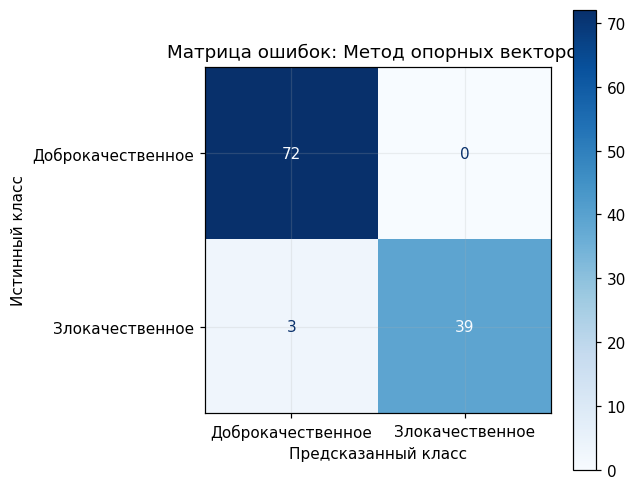

Лучшая модель по CV ROC-AUC: Метод опорных векторов


In [9]:
fig,axes=plt.subplots(1,2,figsize=(16,6))
order=metrics.sort_values('ROC-AUC')
axes[0].barh(order['Модель'],order['ROC-AUC']);axes[0].set(xlim=(0,1.03),xlabel='ROC-AUC',title='Сравнение качества классификаторов')
for name,model in models.items():
    fpr,tpr,_=roc_curve(yte,model.predict_proba(Xte)[:,1]);auc=roc_auc_score(yte,model.predict_proba(Xte)[:,1]);axes[1].plot(fpr,tpr,label=f'{name}: {auc:.3f}',lw=1.5)
axes[1].plot([0,1],[0,1],'k--',label='Случайная модель');axes[1].set(xlabel='Доля ложноположительных ответов',ylabel='Доля истинноположительных ответов',title='ROC-кривые классификаторов');axes[1].legend(fontsize=7,loc='lower right')
fig.tight_layout();fig.savefig(OUT/'comparison_roc.png',dpi=180,bbox_inches='tight');plt.show()
best_name=pd.DataFrame(tuning).sort_values('CV ROC-AUC',ascending=False).iloc[0]['Модель'];best_model=models[best_name]
fig,ax=plt.subplots(figsize=(6,5));ConfusionMatrixDisplay.from_predictions(yte,best_model.predict(Xte),display_labels=['Доброкачественное','Злокачественное'],cmap='Blues',ax=ax);ax.set(xlabel='Предсказанный класс',ylabel='Истинный класс',title='Матрица ошибок: '+best_name);fig.tight_layout();fig.savefig(OUT/'confusion.png',dpi=180);plt.show()
print('Лучшая модель по CV ROC-AUC:',best_name)

**Вывод по графикам раздела 4.** Чем выше столбец ROC-AUC и чем ближе ROC-кривая к левому верхнему углу, тем лучше модель отделяет две категории. Для окончательной интерпретации следует опираться на значения таблицы выше: результаты предыдущего датасета сюда не переносятся.


## 5. Исследование влияния гиперпараметров

Ниже исследуется зависимость качества SVM от `C`, kNN от числа соседей, дерева от максимальной глубины и GaussianNB от сглаживания дисперсии. Каждая точка — средняя ROC-AUC на пяти фолдах; закрашенная область отражает ±1 стандартное отклонение.

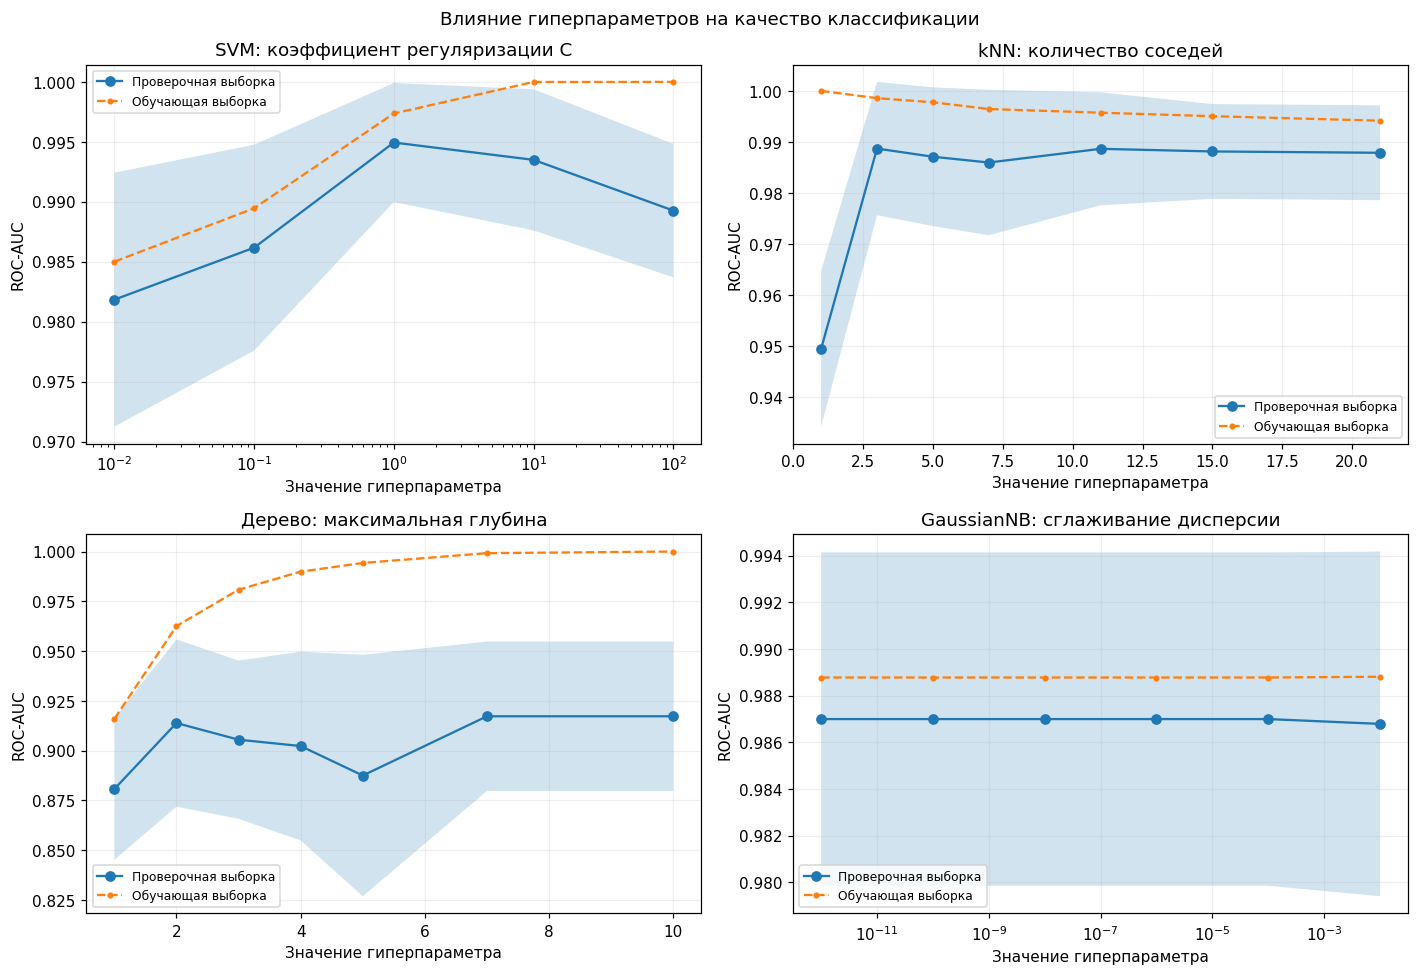

In [10]:
studies=[
 ('SVM: коэффициент регуляризации C',Pipeline([('scale',StandardScaler()),('model',SVC(kernel='rbf'))]),'model__C',[.01,.1,1,10,100],True),
 ('kNN: количество соседей',Pipeline([('scale',StandardScaler()),('model',KNeighborsClassifier())]),'model__n_neighbors',[1,3,5,7,11,15,21],False),
 ('Дерево: максимальная глубина',DecisionTreeClassifier(random_state=SEED),'max_depth',[1,2,3,4,5,7,10],False),
 ('GaussianNB: сглаживание дисперсии',Pipeline([('scale',StandardScaler()),('model',GaussianNB())]),'model__var_smoothing',[1e-12,1e-10,1e-8,1e-6,1e-4,1e-2],True)
]
fig,axes=plt.subplots(2,2,figsize=(13,9))
for ax,(title,est,param,values,logscale) in zip(axes.flat,studies):
    tr,va=validation_curve(est,Xtr,ytr,param_name=param,param_range=values,cv=cv,scoring='roc_auc',n_jobs=1)
    a=np.asarray(values,dtype=float);mu=va.mean(axis=1);sd=va.std(axis=1)
    ax.plot(a,mu,marker='o',label='Проверочная выборка');ax.fill_between(a,mu-sd,mu+sd,alpha=.2)
    ax.plot(a,tr.mean(axis=1),marker='.',linestyle='--',label='Обучающая выборка')
    if logscale:ax.set_xscale('log')
    ax.set(title=title,xlabel='Значение гиперпараметра',ylabel='ROC-AUC');ax.legend(fontsize=8)
fig.suptitle('Влияние гиперпараметров на качество классификации');fig.tight_layout();fig.savefig(OUT/'hyperparameters.png',dpi=180);plt.show()

In [11]:
print('Вывод по гиперпараметрам: максимальные средние ROC-AUC на проверочных фолдах:')
for title, est, param, values, logscale in studies:
    _, scores = validation_curve(est, Xtr, ytr, param_name=param, param_range=values,
                                 cv=cv, scoring='roc_auc', n_jobs=1)
    k = int(np.argmax(scores.mean(axis=1)))
    print(f'— {title}: {param}={values[k]}, ROC-AUC={scores.mean(axis=1)[k]:.4f}')


Вывод по гиперпараметрам: максимальные средние ROC-AUC на проверочных фолдах:
— SVM: коэффициент регуляризации C: model__C=1, ROC-AUC=0.9949
— kNN: количество соседей: model__n_neighbors=3, ROC-AUC=0.9887
— Дерево: максимальная глубина: max_depth=7, ROC-AUC=0.9172
— GaussianNB: сглаживание дисперсии: model__var_smoothing=1e-12, ROC-AUC=0.9870


**Вывод по разделу 5.** Графики показывают изменение средней ROC-AUC на обучении и кросс-валидации при изменении `C` (SVM), числа соседей (kNN), глубины дерева и сглаживания дисперсии (GaussianNB). Если обучающая метрика растёт, а проверочная снижается, это может свидетельствовать о переобучении. Наилучшие значения параметров следует выбирать по максимуму проверочной ROC-AUC, а не по обучающей кривой.


## 6. Нейронная сеть TensorFlow и TensorBoard

Для нейронной сети используются только стандартизированные признаки. Внутри обучающей части выделяется отдельная валидационная выборка; тестовые данные не участвуют в выборе архитектуры. Исследуются 3 конфигурации (число нейронов, dropout, скорость обучения). Применяется ранняя остановка и TensorBoard. **TensorFlow должен быть установлен в выбранном ядре**.

In [12]:
%pip install --upgrade tensorboard

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 23.0.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [13]:
from pathlib import Path

import tensorflow as tf
import numpy as np
import pandas as pd

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

print("Версия TensorFlow:", tf.__version__)

tf.keras.utils.set_random_seed(SEED)


Xnn_tr, Xnn_val, ynn_tr, ynn_val = train_test_split(
    Xtr,
    ytr,
    test_size=0.2,
    stratify=ytr,
    random_state=SEED
)


scaler_nn = StandardScaler().fit(Xnn_tr)

a_tr = scaler_nn.transform(Xnn_tr).astype("float32")
a_val = scaler_nn.transform(Xnn_val).astype("float32")
a_te = scaler_nn.transform(Xte).astype("float32")


configs_nn = [
    {
        "Название": "Малая сеть",
        "Нейроны": 16,
        "Dropout": 0.0,
        "Скорость": 0.001
    },
    {
        "Название": "Средняя сеть",
        "Нейроны": 32,
        "Dropout": 0.2,
        "Скорость": 0.001
    },
    {
        "Название": "Большая сеть",
        "Нейроны": 64,
        "Dropout": 0.35,
        "Скорость": 0.0005
    }
]


def make_nn(c):
    return tf.keras.Sequential([
        tf.keras.layers.Input(shape=(Xtr.shape[1],)),
        tf.keras.layers.Dense(
            c["Нейроны"],
            activation="relu"
        ),
        tf.keras.layers.Dropout(c["Dropout"]),
        tf.keras.layers.Dense(
            c["Нейроны"] // 2,
            activation="relu"
        ),
        tf.keras.layers.Dense(
            1,
            activation="sigmoid"
        )
    ])



TB_ROOT = Path("C:/lab2_tensorboard_logs")
TB_ROOT.mkdir(parents=True, exist_ok=True)


networks = {}
histories = {}
nn_rows = []


for run_index, c in enumerate(configs_nn, start=1):

    print("\nОбучение:", c["Название"])

    tf.keras.backend.clear_session()
    tf.keras.utils.set_random_seed(SEED)

    model = make_nn(c)

    model.compile(
        optimizer=tf.keras.optimizers.Adam(
            learning_rate=c["Скорость"]
        ),
        loss="binary_crossentropy",
        metrics=[
            tf.keras.metrics.AUC(name="auc"),
            tf.keras.metrics.BinaryAccuracy(name="accuracy")
        ]
    )

   
    logdir = TB_ROOT / f"network_{run_index}"
    logdir.mkdir(parents=True, exist_ok=True)

    print("TensorBoard:", logdir)

    callbacks = [
        tf.keras.callbacks.EarlyStopping(
            monitor="val_auc",
            mode="max",
            patience=15,
            restore_best_weights=True
        ),
        tf.keras.callbacks.TensorBoard(
            log_dir=str(logdir),
            histogram_freq=0
        )
    ]

   
    history = model.fit(
        a_tr,
        ynn_tr.to_numpy(),
        validation_data=(
            a_val,
            ynn_val.to_numpy()
        ),
        epochs=100,
        batch_size=32,
        verbose=1,
        callbacks=callbacks
    )

    networks[c["Название"]] = model
    histories[c["Название"]] = history.history

   
    val_prob = model.predict(
        a_val,
        verbose=0
    ).ravel()

    val_pred = (val_prob >= 0.5).astype(int)

    nn_rows.append({
        "Сеть": c["Название"],
        "Эпох": len(history.history["loss"]),
        "Нейроны": c["Нейроны"],
        "Dropout": c["Dropout"],
        "Скорость обучения": c["Скорость"],
        "Валидационный ROC-AUC": roc_auc_score(
            ynn_val, val_prob
        ),
        "Валидационный F1": f1_score(
            ynn_val, val_pred
        )
    })



result_nn = pd.DataFrame(nn_rows).sort_values(
    "Валидационный ROC-AUC",
    ascending=False
)

display(result_nn.round(4))

result_nn.to_csv(
    OUT / "nn_validation.csv",
    index=False,
    encoding="utf-8-sig"
)


selected = result_nn.iloc[0]["Сеть"]
chosen_nn = networks[selected]

print("\nЛучшая нейронная сеть:", selected)


p = chosen_nn.predict(
    a_te,
    verbose=0
).ravel()

q = (p >= 0.5).astype(int)

final_nn = pd.DataFrame([{
    "Модель": "Нейронная сеть: " + selected,
    "Accuracy": accuracy_score(yte, q),
    "Precision": precision_score(yte, q, zero_division=0),
    "Recall": recall_score(yte, q, zero_division=0),
    "F1": f1_score(yte, q, zero_division=0),
    "ROC-AUC": roc_auc_score(yte, p)
}])

display(final_nn.round(4))

final_nn.to_csv(
    OUT / "nn_test_metrics.csv",
    index=False,
    encoding="utf-8-sig"
)

print("\nTensorBoard журналы:", TB_ROOT)

Версия TensorFlow: 2.21.0

Обучение: Малая сеть

TensorBoard: C:\lab2_tensorboard_logs\network_1
Epoch 1/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 4s 67ms/step - accuracy: 0.6044 - auc: 0.6243 - loss: 0.6717 - val_accuracy: 0.6923 - val_auc: 0.7693 - val_loss: 0.6074
Epoch 2/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step - accuracy: 0.7390 - auc: 0.8718 - loss: 0.5594 - val_accuracy: 0.8022 - val_auc: 0.9151 - val_loss: 0.5136
Epoch 3/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 32ms/step - accuracy: 0.8049 - auc: 0.9521 - loss: 0.4819 - val_accuracy: 0.8901 - val_auc: 0.9672 - val_loss: 0.4454
Epoch 4/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step - accuracy: 0.8736 - auc: 0.9758 - loss: 0.4209 - val_accuracy: 0.9231 - val_auc: 0.9791 - val_loss: 0.3914
Epoch 5/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step - accuracy: 0.9011 - auc: 0.9851 - loss: 0.3686 - val_accuracy: 0.9451 - val_auc: 0.9840 - val_loss: 0.3459
Epoch 6/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step - accuracy: 0.9313 - auc: 0.9898 - loss: 0.3220 - v

,Сеть,Эпох,Нейроны,Dropout,Скорость обучения,Валидационный ROC-AUC,Валидационный F1
2,Большая сеть,53,64,0.35,0.0005,0.9964,0.9706
1,Средняя сеть,51,32,0.20,0.0010,0.9954,0.9412
0,Малая сеть,37,16,0.00,0.0010,0.9933,0.9552



Лучшая нейронная сеть: Большая сеть


,Модель,Accuracy,Precision,Recall,F1,ROC-AUC
0,Нейронная сеть: Большая сеть,0.9825,1.0,0.9524,0.9756,0.9974



TensorBoard журналы: C:\lab2_tensorboard_logs


In [14]:
top = result_nn.iloc[0]
print(f"Вывод по нейросетям: лучшая по валидационной ROC-AUC — «{top['Сеть']}» "
      f"({top['Валидационный ROC-AUC']:.4f}), F1={top['Валидационный F1']:.4f}, "
      f"эпох={int(top['Эпох'])}.")
print(f"На тесте выбранная сеть: Accuracy={final_nn.iloc[0]['Accuracy']:.4f}, "
      f"Recall={final_nn.iloc[0]['Recall']:.4f}, ROC-AUC={final_nn.iloc[0]['ROC-AUC']:.4f}.")


Вывод по нейросетям: лучшая по валидационной ROC-AUC — «Большая сеть» (0.9964), F1=0.9706, эпох=53.
На тесте выбранная сеть: Accuracy=0.9825, Recall=0.9524, ROC-AUC=0.9974.


**Вывод по разделу 6.** Сравниваются три архитектуры нейронной сети по валидационным ROC-AUC и F1. Значения, число эпох и название лучшей сети выводятся непосредственно в ячейке обучения. Архитектура выбирается по **валидационной** ROC-AUC, а тестовые метрики вычисляются один раз для выбранной сети. Числа из старого эксперимента с цифрами удалены.


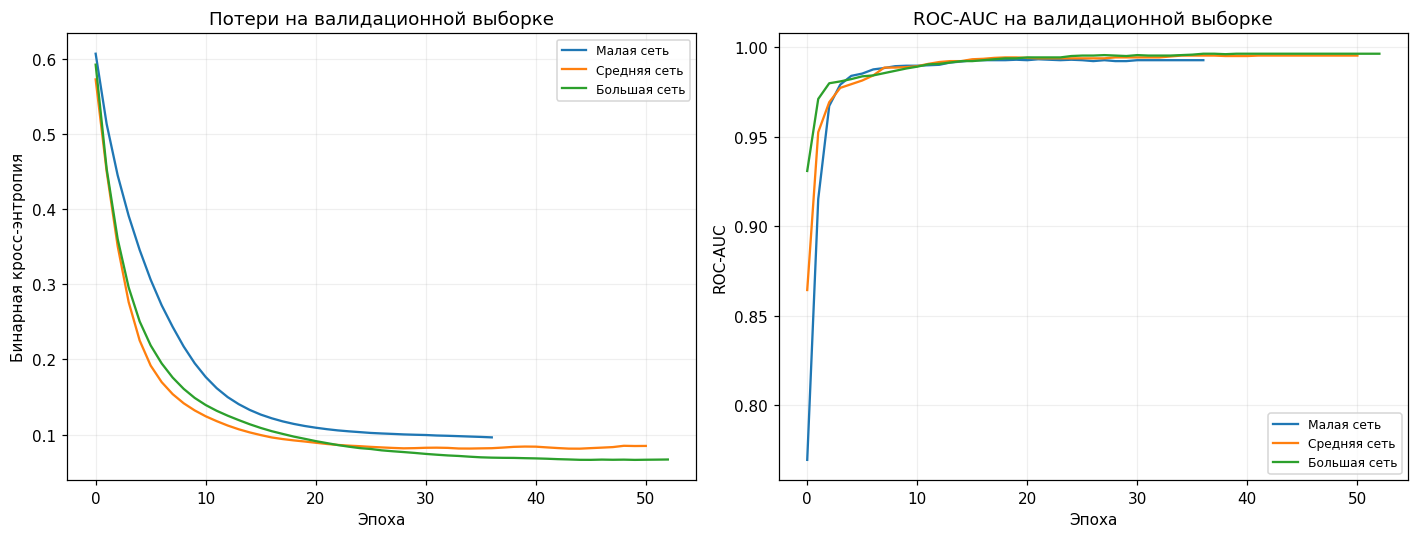

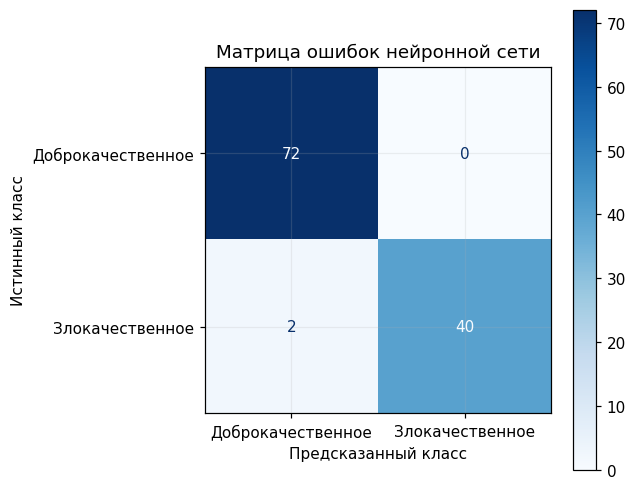

In [15]:
fig,axes=plt.subplots(1,2,figsize=(13,5))
for name,h in histories.items():
    axes[0].plot(h['val_loss'],label=name)
    axes[1].plot(h['val_auc'],label=name)
axes[0].set(title='Потери на валидационной выборке',xlabel='Эпоха',ylabel='Бинарная кросс-энтропия')
axes[1].set(title='ROC-AUC на валидационной выборке',xlabel='Эпоха',ylabel='ROC-AUC')
for ax in axes:ax.legend(fontsize=8)
fig.tight_layout();fig.savefig(OUT/'nn_learning.png',dpi=180);plt.show()
fig,ax=plt.subplots(figsize=(6,5));ConfusionMatrixDisplay.from_predictions(yte,q,display_labels=['Доброкачественное','Злокачественное'],cmap='Blues',ax=ax);ax.set(xlabel='Предсказанный класс',ylabel='Истинный класс',title='Матрица ошибок нейронной сети');fig.tight_layout();fig.savefig(OUT/'nn_confusion.png',dpi=180);plt.show()

**Вывод по графикам обучения.** Снижение валидационной функции потерь указывает на улучшение вероятностных прогнозов, а рост валидационной ROC-AUC — на улучшение разделения категорий. Если потери на валидации начинают расти при продолжении обучения, возможно переобучение. Ранняя остановка позволяет сохранить веса с лучшим `val_auc`.


### Просмотр TensorBoard

Журналы трёх сетей записываются в `TB_ROOT` (значение печатается после обучения). В Jupyter можно открыть TensorBoard ячейкой ниже; при проблемах с отображением в VS Code используйте внешний браузер и команду `python -m tensorboard.main --logdir C:\lab2_tensorboard_logs --port 6007`.


In [19]:
%load_ext tensorboard
%tensorboard --logdir C:/lab2_tensorboard_logs --port 6007


The tensorboard extension is already loaded. To reload it, use:
  %reload_ext tensorboard


Launching TensorBoard...

**Вывод по TensorBoard.** TensorBoard предназначен для сравнения журналов трёх экспериментов (`network_1`, `network_2`, `network_3`): потерь, ROC-AUC и Accuracy на обучении и валидации. Само наличие файлов журнала не доказывает, что веб-интерфейс был открыт; вывод следует уточнить после просмотра графиков.


## 7. Итоговое сравнение и выводы

,Модель,Accuracy,Precision,Recall,F1,ROC-AUC
8,Нейронная сеть: Большая сеть,0.9825,1.0000,0.9524,0.9756,0.9974
0,Линейный дискриминантный анализ,0.9649,1.0000,0.9048,0.9500,0.9970
1,Метод опорных векторов,0.9737,1.0000,0.9286,0.9630,0.9947
2,Гауссовский Байес,0.9211,0.9231,0.8571,0.8889,0.9891
3,Бернуллиевский Байес,0.9386,0.9487,0.8810,0.9136,0.9876
4,Метод ближайших соседей,0.9474,0.9737,0.8810,0.9250,0.9823
5,Дерево решений,0.9123,0.9000,0.8571,0.8780,0.9570
6,Комплементарный Байес,0.8070,0.7174,0.7857,0.7500,0.9276
7,Мультиномиальный Байес,0.8246,1.0000,0.5238,0.6875,0.9276


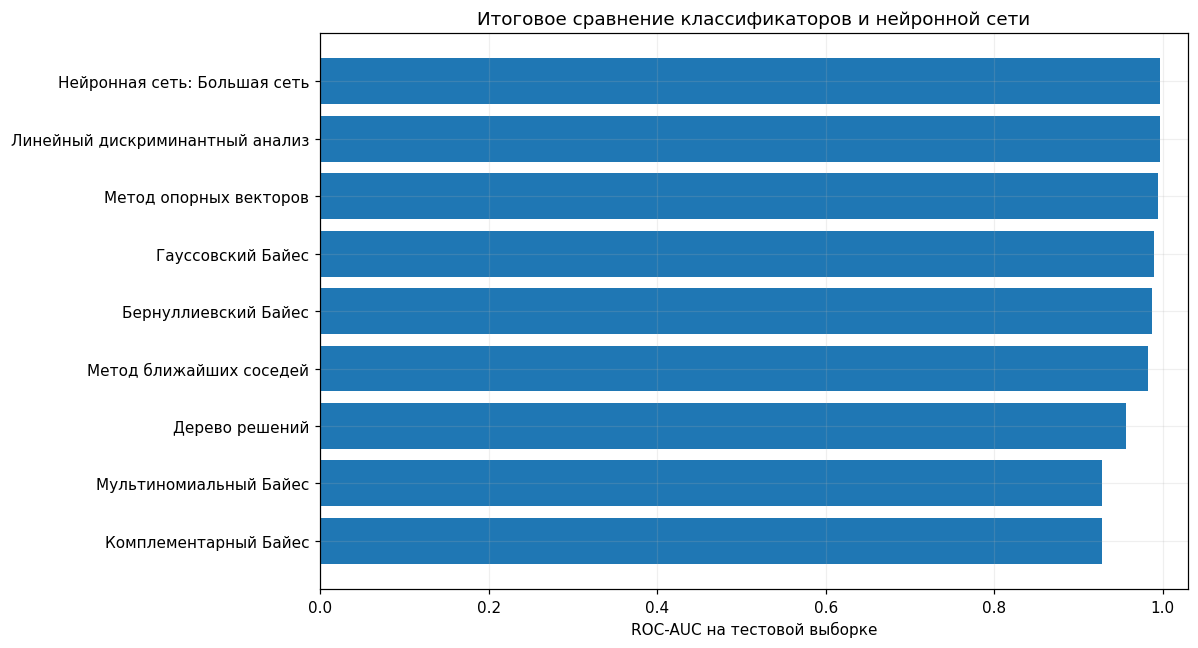

Лучшая классическая модель по кросс-валидации: Метод опорных векторов
Выбранная нейросеть по валидации: Большая сеть


In [17]:
all_metrics=pd.concat([metrics[['Модель','Accuracy','Precision','Recall','F1','ROC-AUC']],final_nn],ignore_index=True)
display(all_metrics.sort_values('ROC-AUC',ascending=False).round(4))
all_metrics.to_csv(OUT/'final_comparison.csv',index=False,encoding='utf-8-sig')
fig,ax=plt.subplots(figsize=(11,6));tmp=all_metrics.sort_values('ROC-AUC');ax.barh(tmp['Модель'],tmp['ROC-AUC']);ax.set(xlabel='ROC-AUC на тестовой выборке',title='Итоговое сравнение классификаторов и нейронной сети',xlim=(0,1.03));fig.tight_layout();fig.savefig(OUT/'final_comparison.png',dpi=180,bbox_inches='tight');plt.show()
print('Лучшая классическая модель по кросс-валидации:',best_name)
print('Выбранная нейросеть по валидации:',selected)

In [18]:
ranked = all_metrics.sort_values('ROC-AUC', ascending=False)
top = ranked.iloc[0]
print(f"Итоговый вывод: лучший тестовый ROC-AUC показала модель «{top['Модель']}» "
      f"({top['ROC-AUC']:.4f}); Accuracy={top['Accuracy']:.4f}, F1={top['F1']:.4f}, "
      f"Recall={top['Recall']:.4f}.")


Итоговый вывод: лучший тестовый ROC-AUC показала модель «Нейронная сеть: Большая сеть» (0.9974); Accuracy=0.9825, F1=0.9756, Recall=0.9524.


**Вывод по разделу 7.** Общая таблица сопоставляет восемь классических методов и выбранную нейронную сеть **на одной тестовой выборке табличных данных**. Победителя следует определять по вычисленным метрикам, учитывая не только Accuracy, но и Recall положительного класса, F1 и ROC-AUC. Старые результаты по чётности рукописных цифр не используются.


## 8. Заключение

В лабораторной работе поставлена задача **бинарной классификации категориальной целевой переменной по строкам таблицы** на наборе Breast Cancer Wisconsin (Diagnostic). Исследуются 30 числовых признаков и две категории диагноза. Реализованы четыре разновидности наивного Байеса, дерево решений, линейный дискриминантный анализ, SVM и kNN. Выполнены подбор гиперпараметров, исследование проверочных кривых, обучение трёх конфигураций нейронной сети TensorFlow и подготовка журналов TensorBoard.

**Итоговые численные выводы следует брать из таблиц и автоматически формируемых комментариев после повторного выполнения всех ячеек.** Результаты на новом датасете могут существенно отличаться от прежних, поэтому они не подменяются значениями из эксперимента с изображениями.


## 9. Источники

1. Scikit-learn. *Breast cancer wisconsin (diagnostic) dataset*: https://scikit-learn.org/stable/modules/generated/sklearn.datasets.load_breast_cancer.html
2. UCI Machine Learning Repository. *Breast Cancer Wisconsin (Diagnostic)*: https://archive.ics.uci.edu/dataset/17/breast+cancer+wisconsin+diagnostic
3. Scikit-learn. *GridSearchCV*: https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.GridSearchCV.html
4. TensorFlow. *Keras*: https://www.tensorflow.org/guide/keras
5. TensorBoard. *Get started*: https://www.tensorflow.org/tensorboard/get_started
